# ERP Visualization

In [35]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

import sys
sys.path.append('../..')
from data.data_configs import *
from data.data_loader import DataLoader

In [ ]:
def plot_fixation_erp_across_subjects(
    subjects,
    channels,
    pre_window_ms=500,
    post_window_ms=1000,
    target_label=1,
    nontarget_label=0,
    ci=0.95,
    xlim_ms=None,
    title=None,
    figsize=(8, 5),
):


    # Load EEG data (always full epoch)
    X, y, time_axis, subject_ids = DataLoader().load_labeled_eeg_data(
        subjects=subjects,
        channels=channels,
        pre_window_ms=pre_window_ms,
        post_window_ms=post_window_ms,
    )

    # Split by condition
    X_target = X[y == target_label]
    X_nontarget = X[y == nontarget_label]

    if len(X_target) == 0 or len(X_nontarget) == 0:
        raise ValueError("No epochs found for one of the conditions.")

    # Average across channels first (epochs × time)
    X_target = X_target.mean(axis=1)
    X_nontarget = X_nontarget.mean(axis=1)

    def mean_ci(data):
        mean = data.mean(axis=0)
        sem = data.std(axis=0, ddof=1) / np.sqrt(data.shape[0])
        z = 1.96  # 95% CI
        return mean, sem * z

    target_mean, target_ci = mean_ci(X_target)
    nontarget_mean, nontarget_ci = mean_ci(X_nontarget)

    # ---- Plot ----
    fig, ax = plt.subplots(figsize=figsize)

    ax.plot(time_axis, target_mean, linewidth=2, label="Target")
    ax.fill_between(
        time_axis,
        target_mean - target_ci,
        target_mean + target_ci,
        alpha=0.25,
    )

    ax.plot(time_axis, nontarget_mean, linewidth=2, label="Non-Target")
    ax.fill_between(
        time_axis,
        nontarget_mean - nontarget_ci,
        nontarget_mean + nontarget_ci,
        alpha=0.25,
    )

    ax.axvline(0, linestyle="--", linewidth=1)

    ax.set_xlabel("Time (ms)")
    ax.set_ylabel("Amplitude (µV)")
    ax.set_title(title or f"Fixation-locked ERP ({', '.join(channels)})")
    ax.legend()
    ax.grid(alpha=0.3)

    if xlim_ms is not None:
        ax.set_xlim(xlim_ms)

    plt.tight_layout()
    plt.show()


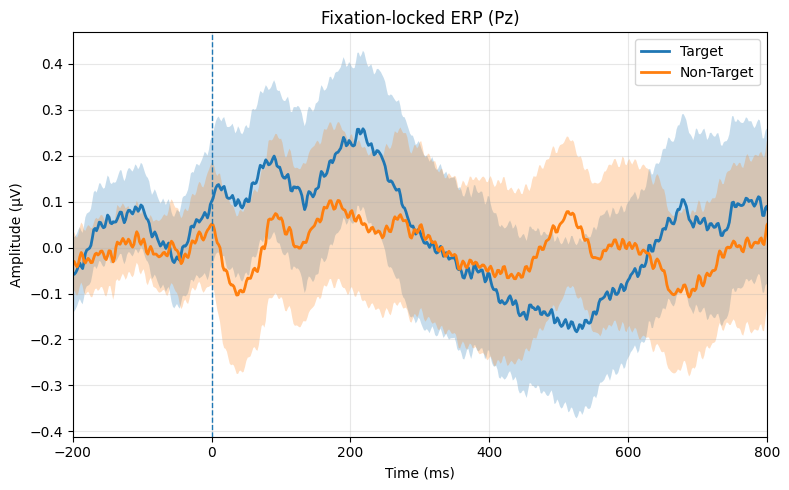

In [40]:
plot_fixation_erp_across_subjects(
    subjects=SUBJECTS,
    channels=['Pz'],
    xlim_ms=(-200, 800),           # only show part of the epoch
)


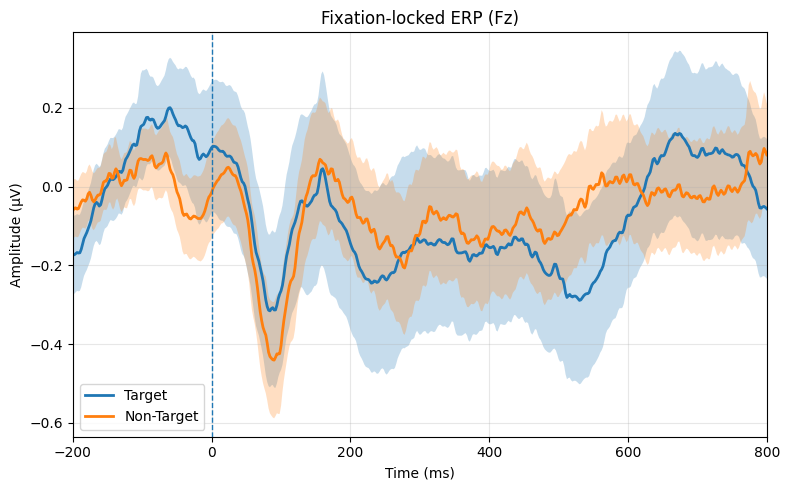

In [41]:
plot_fixation_erp_across_subjects(
    subjects=SUBJECTS,
    channels=['Fz'],
    xlim_ms=(-200, 800),           # only show part of the epoch
)


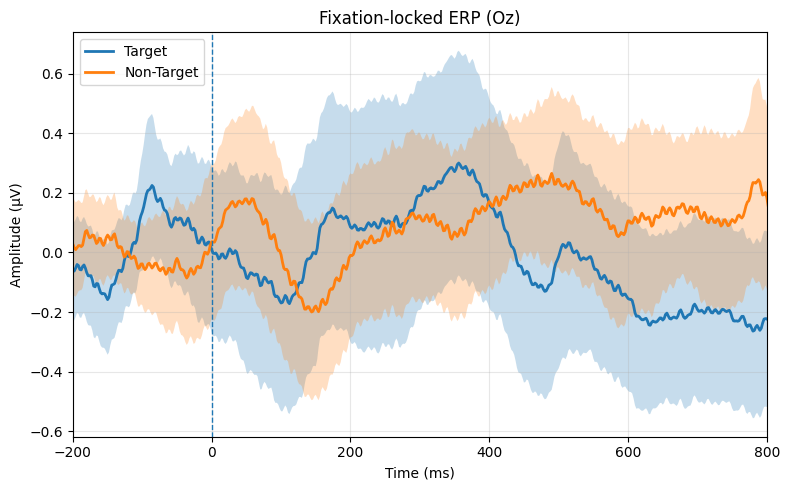

In [42]:
plot_fixation_erp_across_subjects(
    subjects=SUBJECTS,
    channels=['Oz'],
    xlim_ms=(-200, 800),           # only show part of the epoch
)


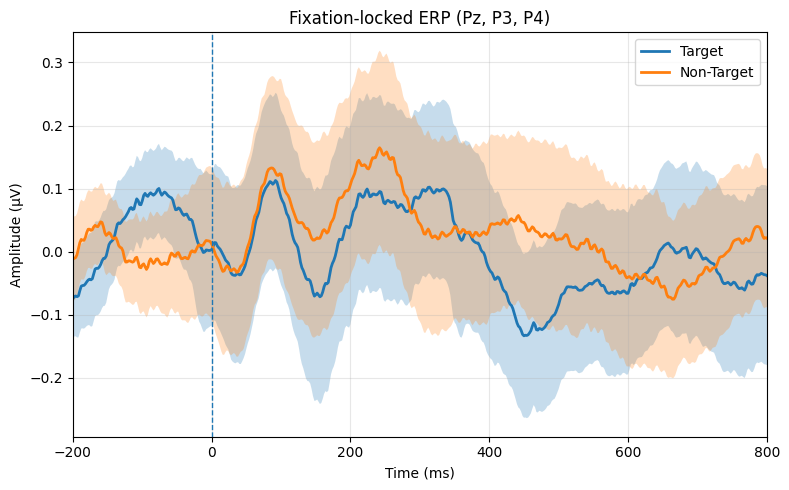

In [43]:
plot_fixation_erp_across_subjects(
    subjects=SUBJECTS,
    channels=['Pz', 'P3', 'P4'],
    xlim_ms=(-200, 800),           # only show part of the epoch
)


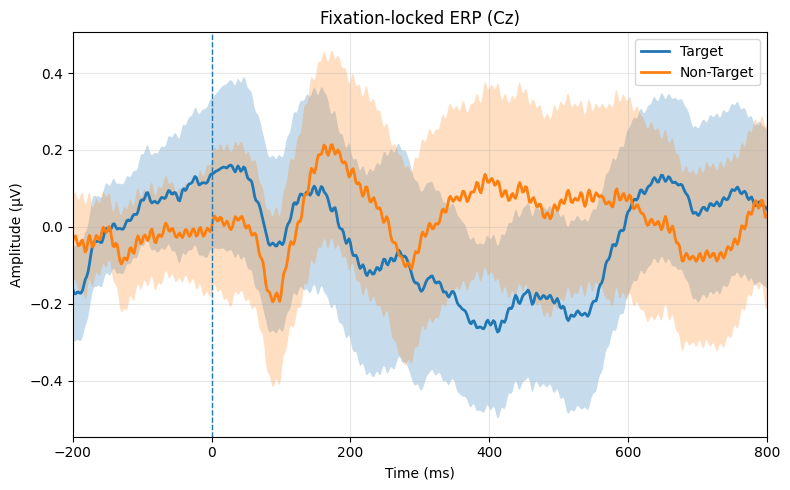

In [47]:
plot_fixation_erp_across_subjects(
    subjects=SUBJECTS,
    channels=['Cz'],
    xlim_ms=(-200, 800),           # only show part of the epoch
)


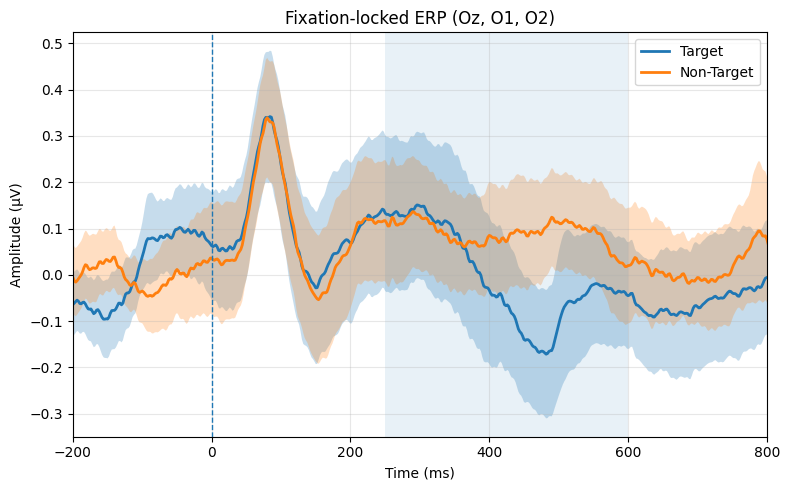

In [ ]:
plot_fixation_erp_across_subjects(
    subjects=SUBJECTS,
    channels=['Oz', 'O1', 'O2'],
    xlim_ms=(-200, 800),           # only show part of the epoch
)
